# Multi-Branch Model - Huấn luyện mô hình đa nhánh

---

Mục tiêu là xây dựng một mô hình đa nhánh, đầu vào là `RBG` và đi vào cách nhánh với mỗi nhánh nhận một đặc điểm của ảnh và vai trò khác nhau nhằm trích xuất ra đặc trưng tốt nhât dể gộp vào lớp cuối cùng và phân loại ra `real` và `spoof`.

In [ ]:
import os
import sys
import math
import pandas as pd
import numpy as np
from pathlib import Path

os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0' 

import tensorflow as tf
from keras.models import load_model, Sequential
from keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomTranslation, RandomContrast, RandomBrightness
from keras.optimizers import AdamW
from keras.optimizers.schedules import CosineDecay
from keras.losses import BinaryFocalCrossentropy
from keras.callbacks import EarlyStopping
from keras.utils import set_random_seed, image_dataset_from_directory
from sklearn.metrics import classification_report

sys.path.append(os.path.abspath('..'))
from models.MultiBranchModel import multibranch_model
from src.evaluate import MetricsCallback, plot_training_history, evaluate_model, calculate_metrics

I0000 00:00:1791706840.204969  290255 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
IMG_SIZE = 224
EPOCHS = 30
LR_WARMUP_EPOCHS = 2
BATCH_SIZE = 32
SEED = 42
DATA_DIR = Path('../datasets/LCC_FASD')
OUTPUT_DIR = Path('../outputs/multibranch-model')
CACHE_DIR = Path('../cache/multibranch-model')

set_random_seed(SEED)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Chuẩn bị dữ liệu

---

In [3]:
data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomTranslation(0.1, 0.1, interpolation='nearest'),
    RandomRotation(factor=0.015, interpolation='nearest'),
    RandomContrast(factor=0.2),
    RandomBrightness(factor=0.1),
])

E0000 00:00:1791706843.526528  290255 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [4]:
train_dir = DATA_DIR / 'train'
val_dir = DATA_DIR / 'val'
test_dir = DATA_DIR / 'test'

print("Tập Train:")
train_ds_raw = image_dataset_from_directory(
    train_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=True,
    seed=SEED
)

print("\nTập Validation:")
val_ds_raw = image_dataset_from_directory(
    val_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=False
)

print("\nTập Test:")
test_ds_raw = image_dataset_from_directory(
    test_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=False
)

print("Class:", train_ds_raw.class_names)

Tập Train:
Found 8299 files belonging to 2 classes.

Tập Validation:
Found 2948 files belonging to 2 classes.

Tập Test:
Found 7580 files belonging to 2 classes.
Class: ['real', 'spoof']


In [5]:
AUTOTUNE = tf.data.AUTOTUNE
to_uint8 = lambda x, y: (tf.cast(tf.round(x), tf.uint8), y)
to_float = lambda x, y: (tf.cast(x, tf.float32), y)
augment  = lambda x, y: (data_augmentation(tf.cast(x, tf.float32), training=True), y)

def make_cached(ds, path=None):
    ds = ds.map(to_uint8)
    ds = ds.cache(str(path)) if path else ds.cache()
    for _ in ds:
        pass
    return ds

train_c = make_cached(train_ds_raw)                      
val_c   = make_cached(val_ds_raw)                       
test_c  = make_cached(test_ds_raw, CACHE_DIR / 'test') 

train_ds = (train_c.shuffle(2000, seed=SEED).batch(BATCH_SIZE).map(augment, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE))
val_ds  = val_c.batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE)
test_ds = test_c.batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE)

## 2. Khởi tạo mô hình

---

Mô hình được xây dựng trong [MultiBranchModel](../models/MultiBranchModel.py)

In [6]:
input_shape = (IMG_SIZE, IMG_SIZE, 3)

model = multibranch_model(input_shape=input_shape, num_classes=1)
model.build((None, IMG_SIZE, IMG_SIZE, 3))
model.summary()

Model: "multibranch_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rgb_input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescale (Rescaling) │ (None, 224, 224,  │          0 │ rgb_input[0][0]   │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 224, 224,  │          0 │ rescale[0][0]     │
│                     │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fft_channels        │ (None, 224, 113,  │          0 │ rescale[0][0]     │
│ (Lambda)            │ 2)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ texture_channels    │ (None, 224, 224,  │          0 │ rescale[0][0]     │
│ (Lambda)            │ 11)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ srm_channels        │ (None, 224, 224,  │          0 │ rescale[0][0]     │
│ (Lambda)            │ 9)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ color_branch        │ (None, 14, 14,    │     34,082 │ lambda[0][0]      │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fft_branch          │ (None, 14, 8,     │     32,914 │ fft_channels[0][… │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ texture_branch      │ (None, 14, 14,    │     35,542 │ texture_channels… │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_branch          │ (None, 28, 28,    │     37,046 │ rescale[0][0]     │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ srm_branch          │ (None, 14, 14,    │     34,958 │ srm_channels[0][… │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ color_branch[0][… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ color_branch[0][… │
│ (GlobalMaxPooling2… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ fft_branch[0][0]  │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ fft_branch[0][0]  │
│ (GlobalMaxPooling2… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ texture_branch[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ texture_branch[0

 Total params: 504,020 (1.92 MB)

 Trainable params: 500,438 (1.91 MB)

 Non-trainable params: 3,582 (13.99 KB)

In [7]:
labels = ["real", "spoof"]
real_counts = 0
spoof_counts = 0

for label in labels:
    label_dir = os.path.join(train_dir, label)
    count = len(os.listdir(label_dir))
    if label == "real":
        real_counts = count
    else:
        spoof_counts = count
    print(f"Số lượng ảnh {label}: {count}")

total_counts = real_counts + spoof_counts
print(f"Tổng số lượng ảnh: {total_counts}")
class_weights = {0: total_counts / (2 * real_counts), 1: total_counts / (2 * spoof_counts)}
print(f"Class weights: {class_weights}")

Số lượng ảnh real: 1223
Số lượng ảnh spoof: 7076
Tổng số lượng ảnh: 8299
Class weights: {0: 3.392886345053148, 1: 0.5864188807235726}


In [8]:
metrics_callback = MetricsCallback(val_dataset=val_ds, save_dir=OUTPUT_DIR)

callbacks = [
    metrics_callback,

    EarlyStopping(
        monitor='val_acer', 
        patience=8,
        mode='min',
        restore_best_weights=True,
        verbose=1
    )
]

steps_per_epoch = math.ceil(len(train_ds_raw) / BATCH_SIZE)

warmup_steps = LR_WARMUP_EPOCHS * steps_per_epoch
lr_schedule = CosineDecay(
    initial_learning_rate=0.000363 / 100,
    warmup_target=0.000363,
    warmup_steps=warmup_steps,
    decay_steps=EPOCHS * steps_per_epoch - warmup_steps,
)

In [9]:
output_names = ["texture_output", "color_output", "rgb_output", "fft_output", "srm_output", "final_output"]

w = tf.constant([class_weights[0], class_weights[1]], dtype=tf.float32)

def to_train_multi(x, y):
    sw = tf.gather(w, tf.cast(y[:, 0], tf.int32))
    return x, {n: y for n in output_names}, sw

def to_eval_multi(x, y):
    return x, {n: y for n in output_names}

train_ds_multi = train_ds.map(to_train_multi)
val_ds_multi = val_ds.map(to_eval_multi)

loss_weights = {name: 1.0 for name in output_names}

model.compile(
    optimizer=AdamW(learning_rate=lr_schedule, weight_decay=2e-3),
    loss={name: BinaryFocalCrossentropy(gamma=2.0) for name in output_names},
    loss_weights=loss_weights,
    metrics={"final_output": ["accuracy"]},
)

## 3. Huấn luyện mô hình

---

In [10]:
history = model.fit(
    train_ds_multi,
    validation_data=val_ds_multi,
    epochs=EPOCHS,
    callbacks=callbacks
)

260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - color_output_loss: 0.0985 - fft_output_loss: 0.1644 - final_output_accuracy: 0.9660 - final_output_loss: 0.0227 - loss: 0.7148 - rgb_output_loss: 0.1344 - srm_output_loss: 0.1393 - texture_output_loss: 0.1550 - APCER: 10.11% - BPCER: 7.16% - ACER: 8.63% (t*: 0.6666) 
260/260 ━━━━━━━━━━━━━━━━━━━━ 369s 1s/step - color_output_loss: 0.0985 - fft_output_loss: 0.1644 - final_output_accuracy: 0.9660 - final_output_loss: 0.0227 - loss: 0.7148 - rgb_output_loss: 0.1344 - srm_output_loss: 0.1393 - texture_output_loss: 0.1550 - val_color_output_loss: 0.1523 - val_fft_output_loss: 0.1550 - val_final_output_accuracy: 0.9522 - val_final_output_loss: 0.0526 - val_loss: 0.8207 - val_rgb_output_loss: 0.1674 - val_srm_output_loss: 0.1351 - val_texture_output_loss: 0.1594 - val_apcer: 0.1011 - val_bpcer: 0.0716 - val_acer: 0.0863
Epoch 26/30
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - color_output_loss: 0.0928 - fft_output_loss: 0.1685 - final_output_accuracy: 0.97

## 4. Đánh giá kết quả 

---

In [11]:
model = load_model(OUTPUT_DIR / 'best_model.keras', compile=False)
threshold_best = float(open(OUTPUT_DIR / 'best_threshold.txt').read())
print(f"Ngưỡng tốt nhất: {threshold_best}")

test_preds = model.predict(test_ds)
y_prob = test_preds["final_output"].flatten()
y_pred = (y_prob >= threshold_best).astype(int)

y_true_list = []
for images, labels in test_ds:
    y_true_list.append(labels.numpy())
y_true = np.concatenate(y_true_list)

print(classification_report(y_true, y_pred))

/home/dainguyen1506/Documents/Project/face-anti-spoofing/.venv/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'cbam_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/dainguyen1506/Documents/Project/face-anti-spoofing/.venv/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'cbam_3', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/dainguyen1506/Documents/Project/face-anti-spoofing/.venv

Ngưỡng tốt nhất: 0.45403966307640076
237/237 ━━━━━━━━━━━━━━━━━━━━ 88s 369ms/step
              precision    recall  f1-score   support

         0.0       0.26      0.80      0.39       314
         1.0       0.99      0.90      0.94      7266

    accuracy                           0.90      7580
   macro avg       0.62      0.85      0.67      7580
weighted avg       0.96      0.90      0.92      7580



Đã lưu biểu đồ lịch sử tại: ../outputs/multibranch-model/training_history.png


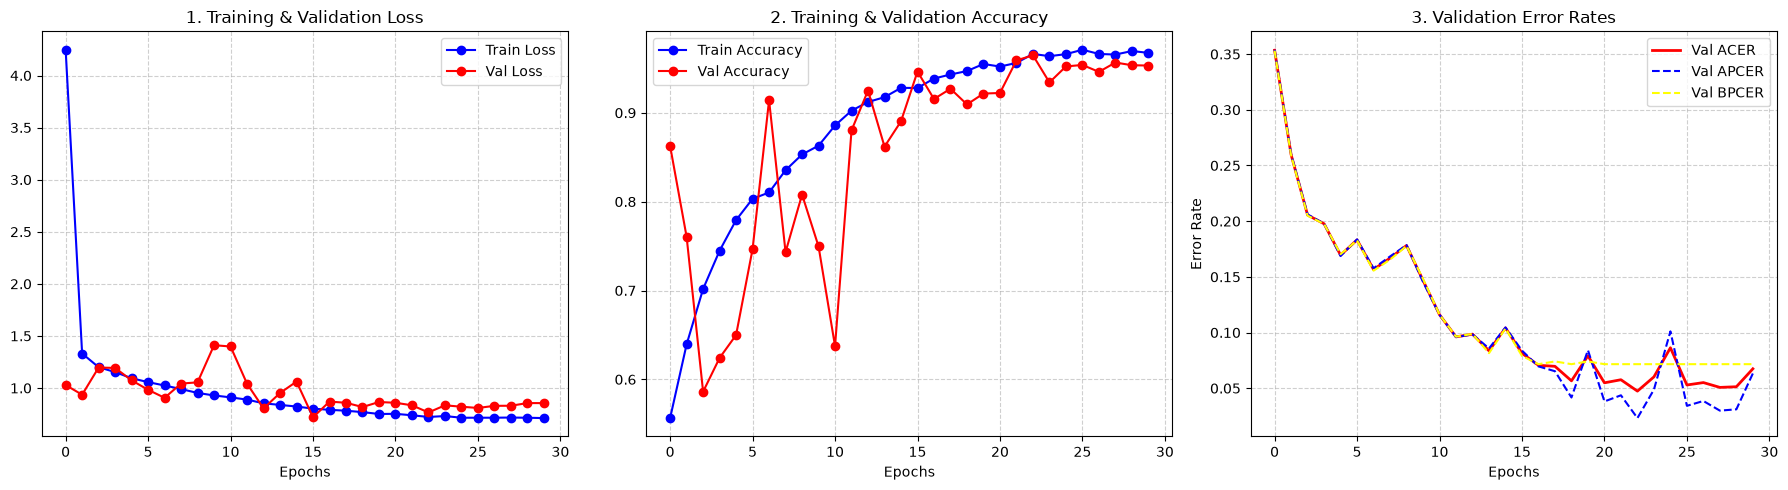

In [12]:
plot_training_history(history.history, output=str(OUTPUT_DIR / 'training_history.png'))

93/93 ━━━━━━━━━━━━━━━━━━━━ 34s 364ms/step
Đã lưu biểu đồ tại: ../outputs/multibranch-model/evaluation_report.png


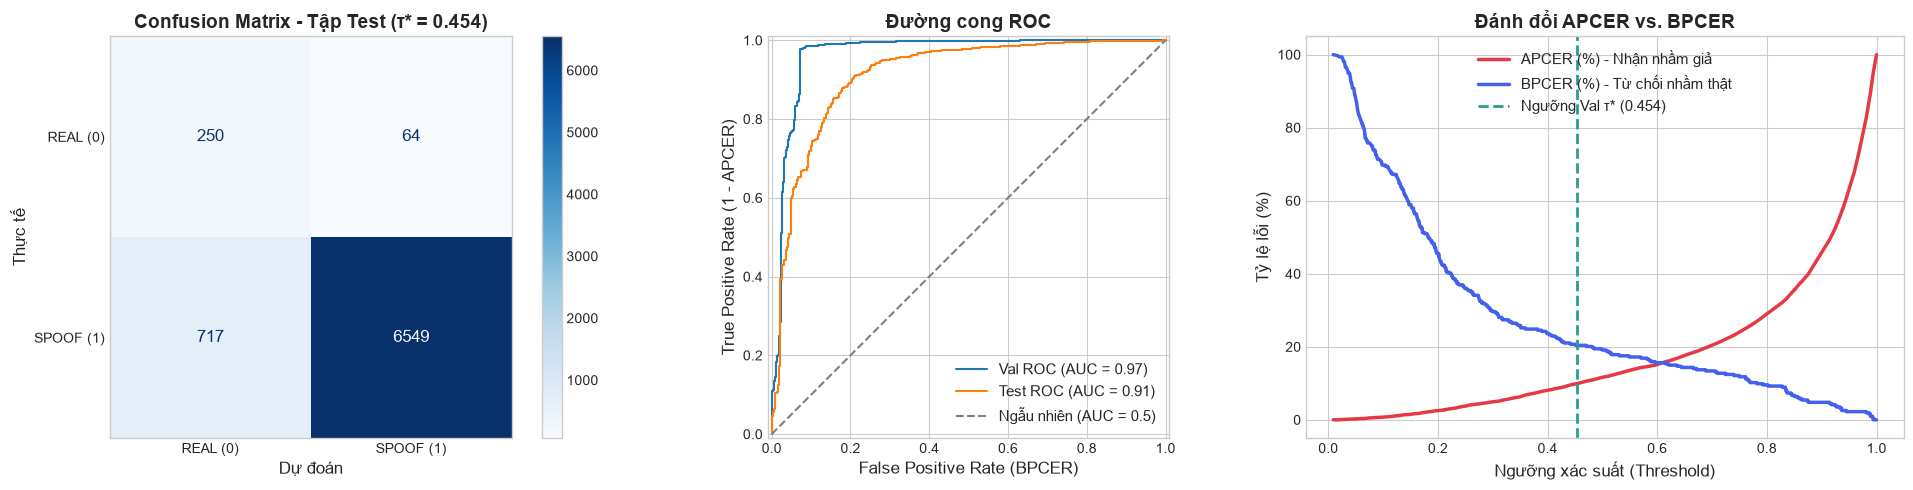

In [ ]:
val_preds = model.predict(val_ds)
y_val_prob = val_preds["final_output"].flatten()

y_val_list = []
for images, labels in val_ds:
    y_val_list.append(labels.numpy())
y_val_true = np.concatenate(y_val_list)

evaluate_model((y_true, y_prob), (y_val_true, y_val_prob), threshold_best, output=str(OUTPUT_DIR / 'evaluation_report.png'))

In [ ]:
from sklearn.metrics import roc_curve

def find_eer_threshold(y_true, y_prob):
    """Tìm ngưỡng mà APCER = BPCER."""
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    fnr = 1 - tpr
    index = np.nanargmin(np.absolute(fnr - fpr))
    return thresholds[index]

In [14]:
branch_names = ["texture_output", "color_output", "rgb_output", "fft_output", "srm_output", "final_output"]

results = []
for name in branch_names:
    threshold = find_eer_threshold(y_val_true, val_preds[name].flatten())
    report = calculate_metrics(y_true.flatten(), test_preds[name].flatten(), threshold)
    results.append({"Branch": name, "Threshold": threshold, **report})

metrics = pd.DataFrame(results)
metrics

,Branch,Threshold,EER (%),APCER (%),BPCER (%),ACER (%),AUC (%),ACC (%)
0,texture_output,0.510708,48.726115,60.253234,36.942675,48.597955,51.480765,40.712401
1,color_output,0.474037,24.840764,21.607487,27.707006,24.657247,82.897813,78.139842
2,rgb_output,0.445869,26.114650,14.024222,41.719745,27.871984,81.984060,84.828496
3,fft_output,0.528685,41.401274,37.159372,45.859873,41.509623,63.485328,62.480211
4,srm_output,0.546077,28.662420,16.818057,41.401274,29.109665,78.761039,82.163588
5,final_output,0.454040,15.605096,9.867878,20.382166,15.125022,91.297527,89.696570
